# Option Pricing: Black-Scholes, Monte Carlo and Binomial Trees

Compares three pricing methods for vanilla options and checks them against each other.
Base case throughout: `S = 100, K = 100, T = 1, r = 5%, sigma = 20%`.

Run `pip install -e .` from the repository root first so that `options_pricing` can be imported.

In [4]:
import numpy as np

In [1]:
from options_pricing import black_scholes_call, black_scholes_put

## 1. Black-Scholes benchmark
Closed-form call/put prices and a put-call parity check.

In [2]:
S = 100
K = 100
T = 1.0
r = 0.05
sigma = 0.20

call_price = black_scholes_call(
    S, K, T, r, sigma
)

put_price = black_scholes_put(
    S, K, T, r, sigma
)

print(f"Call price: {call_price:.6f}")
print(f"Put price:  {put_price:.6f}")

Call price: 10.450584
Put price:  5.573526


In [5]:
parity_left = call_price - put_price

parity_right = (
    S
    - K * np.exp(-r * T)
)

print("C - P:", parity_left)
print("S - K*exp(-rT):", parity_right)
print(
    "Difference:",
    abs(parity_left - parity_right)
)

C - P: 4.877057549928594
S - K*exp(-rT): 4.877057549928594
Difference: 0.0


## 2. Monte Carlo pricing
Plain Monte Carlo under risk-neutral geometric Brownian motion, compared with Black-Scholes.

In [6]:
from options_pricing import monte_carlo_call

In [8]:
mc_price = monte_carlo_call(
    S=100,
    K=100,
    T=1.0,
    r=0.05,
    sigma=0.20,
    n_simulations=100_000,
    seed=42
)

print(f"Monte Carlo price: {mc_price:.6f}")
print(f"Black-Scholes price: {call_price:.6f}")

Monte Carlo price: 10.420541
Black-Scholes price: 10.450584


In [9]:
error = abs(mc_price - call_price)

relative_error = (
    error / call_price * 100
)

print(f"Absolute error: {error:.6f}")
print(f"Relative error: {relative_error:.4f}%")

Absolute error: 0.030042
Relative error: 0.2875%


### Antithetic variates
Each draw `Z` is paired with `-Z`. `n_simulations` is the *total* number of paths (n/2 pairs).

In [12]:
from options_pricing import monte_carlo_call_antithetic

In [13]:
mc_anti_price = monte_carlo_call_antithetic(
    S=100,
    K=100,
    T=1.0,
    r=0.05,
    sigma=0.20,
    n_simulations=100_000,
    seed=42
)

print(f"Antithetic MC price: {mc_anti_price:.6f}")
print(f"Black-Scholes price: {call_price:.6f}")

Antithetic MC price: 10.467314
Black-Scholes price: 10.450584


In [14]:
anti_error = abs(
    mc_anti_price - call_price
)

anti_relative_error = (
    anti_error / call_price * 100
)

print(f"Absolute error: {anti_error:.6f}")
print(f"Relative error: {anti_relative_error:.4f}%")

Absolute error: 0.016731
Relative error: 0.1601%


## 3. Binomial tree (Cox-Ross-Rubinstein)
European call priced by backward induction, plus convergence in the number of steps.

In [15]:
from options_pricing import binomial_call

In [22]:
binomial_price = binomial_call(
    S=100,
    K=100,
    T=1.0,
    r=0.05,
    sigma=0.20,
    n_steps=100
)

print(f"Binomial price: {binomial_price:.6f}")
print(f"Black-Scholes price: {call_price:.6f}")

Binomial price: 10.430612
Black-Scholes price: 10.450584


In [23]:
binomial_error = abs(
    binomial_price - call_price
)

binomial_relative_error = (
    binomial_error / call_price * 100
)

print(
    f"Absolute error: "
    f"{binomial_error:.6f}"
)

print(
    f"Relative error: "
    f"{binomial_relative_error:.4f}%"
)

Absolute error: 0.019972
Relative error: 0.1911%


In [24]:
steps_list = [
    10,
    25,
    50,
    100,
    250,
    500,
    1000
]

for n in steps_list:

    price = binomial_call(
        S=100,
        K=100,
        T=1.0,
        r=0.05,
        sigma=0.20,
        n_steps=n
    )

    error = abs(
        price - call_price
    )

    relative_error = (
        error / call_price * 100
    )

    print(
        f"Steps: {n:4d} | "
        f"Price: {price:.6f} | "
        f"Error: {relative_error:.4f}%"
    )

Steps:   10 | Price: 10.253409 | Error: 1.8867%
Steps:   25 | Price: 10.520966 | Error: 0.6735%
Steps:   50 | Price: 10.410692 | Error: 0.3817%
Steps:  100 | Price: 10.430612 | Error: 0.1911%
Steps:  250 | Price: 10.442589 | Error: 0.0765%
Steps:  500 | Price: 10.446585 | Error: 0.0383%
Steps: 1000 | Price: 10.448584 | Error: 0.0191%


## 4. Method comparison
All methods against the Black-Scholes price.

In [26]:
# ============================================
# FINAL METHOD COMPARISON
# ============================================

# Black-Scholes benchmark
bs_price = call_price

# Standard Monte Carlo
standard_mc_price = mc_price

# Antithetic Monte Carlo
antithetic_mc_price = mc_anti_price

# CRR Binomial Tree - explicitly use 1000 steps
binomial_1000_price = binomial_call(
    S=100,
    K=100,
    T=1.0,
    r=0.05,
    sigma=0.20,
    n_steps=1000
)

methods = {
    "Black-Scholes": bs_price,
    "Monte Carlo": standard_mc_price,
    "Antithetic Monte Carlo": antithetic_mc_price,
    "Binomial Tree (1000)": binomial_1000_price
}

for method, price in methods.items():

    error = abs(price - bs_price)
    relative_error = error / bs_price * 100

    print(
        f"{method:25s} "
        f"Price: {price:.6f} | "
        f"Error: {relative_error:.4f}%"
    )

Black-Scholes             Price: 10.450584 | Error: 0.0000%
Monte Carlo               Price: 10.420541 | Error: 0.2875%
Antithetic Monte Carlo    Price: 10.467314 | Error: 0.1601%
Binomial Tree (1000)      Price: 10.448584 | Error: 0.0191%


## 5. Monte Carlo convergence
Error and standard error as the number of simulations grows. The standard error should shrink like 1/sqrt(N), i.e. a log-log slope of -0.5.

In [27]:
simulation_sizes = [
    1_000,
    5_000,
    10_000,
    50_000,
    100_000,
    500_000,
    1_000_000,
    5_000_000
]

mc_results = []

for n in simulation_sizes:

    price = monte_carlo_call(
        S=100,
        K=100,
        T=1.0,
        r=0.05,
        sigma=0.20,
        n_simulations=n,
        seed=42
    )

    error = abs(price - call_price)
    relative_error = error / call_price * 100

    mc_results.append({
        "simulations": n,
        "price": price,
        "relative_error_%": relative_error
    })

    print(
        f"Simulations: {n:>8,} | "
        f"Price: {price:.6f} | "
        f"Error: {relative_error:.4f}%"
    )

Simulations:    1,000 | Price: 9.911980 | Error: 5.1538%
Simulations:    5,000 | Price: 10.168920 | Error: 2.6952%
Simulations:   10,000 | Price: 10.345182 | Error: 1.0086%
Simulations:   50,000 | Price: 10.457692 | Error: 0.0680%
Simulations:  100,000 | Price: 10.420541 | Error: 0.2875%
Simulations:  500,000 | Price: 10.450050 | Error: 0.0051%
Simulations: 1,000,000 | Price: 10.453195 | Error: 0.0250%
Simulations: 5,000,000 | Price: 10.458798 | Error: 0.0786%


In [28]:
# ============================================
# MONTE CARLO CONVERGENCE
# Nested simulations: 1K -> 5M
# ============================================

simulation_sizes = [
    1_000,
    5_000,
    10_000,
    50_000,
    100_000,
    500_000,
    1_000_000,
    5_000_000
]

rng = np.random.default_rng(42)

# Generate one common set of 5M random numbers
Z_all = rng.standard_normal(5_000_000)

mc_convergence = []

for n in simulation_sizes:

    Z = Z_all[:n]

    ST = 100 * np.exp(
        (0.05 - 0.5 * 0.20**2) * 1.0
        + 0.20 * np.sqrt(1.0) * Z
    )

    payoff = np.maximum(ST - 100, 0)

    price = np.exp(-0.05 * 1.0) * np.mean(payoff)

    error = abs(price - call_price)

    relative_error = (
        error / call_price * 100
    )

    mc_convergence.append({
        "simulations": n,
        "price": price,
        "absolute_error": error,
        "relative_error_%": relative_error
    })

    print(
        f"Simulations: {n:>9,} | "
        f"Price: {price:.6f} | "
        f"Error: {relative_error:.4f}%"
    )

Simulations:     1,000 | Price: 9.911980 | Error: 5.1538%
Simulations:     5,000 | Price: 10.168920 | Error: 2.6952%
Simulations:    10,000 | Price: 10.345182 | Error: 1.0086%
Simulations:    50,000 | Price: 10.457692 | Error: 0.0680%
Simulations:   100,000 | Price: 10.420541 | Error: 0.2875%
Simulations:   500,000 | Price: 10.450050 | Error: 0.0051%
Simulations: 1,000,000 | Price: 10.453195 | Error: 0.0250%
Simulations: 5,000,000 | Price: 10.458798 | Error: 0.0786%


In [32]:
import pandas as pd

In [33]:
mc_convergence_df = pd.DataFrame(mc_convergence)
mc_convergence_df

,simulations,price,absolute_error,relative_error_%
0,1000,9.911980,0.538604,5.153817
1,5000,10.168920,0.281664,2.695196
2,10000,10.345182,0.105402,1.008571
3,50000,10.457692,0.007108,0.068015
4,100000,10.420541,0.030042,0.287471
5,500000,10.450050,0.000534,0.005108
6,1000000,10.453195,0.002612,0.024991
7,5000000,10.458798,0.008215,0.078606


In [35]:
import matplotlib.pyplot as plt

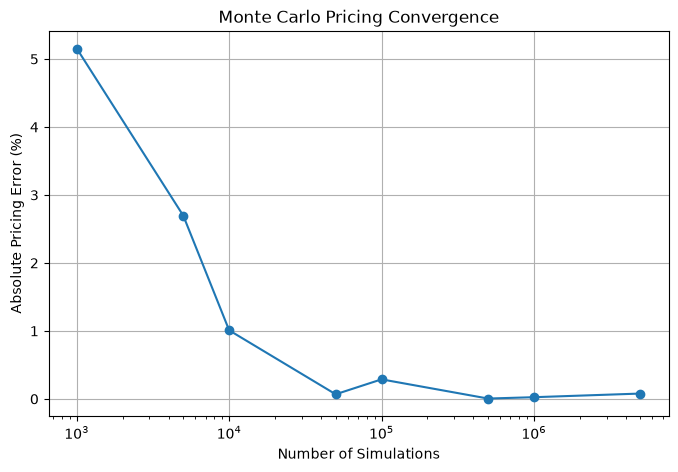

In [36]:
plt.figure(figsize=(8, 5))

plt.plot(
    mc_convergence_df["simulations"],
    mc_convergence_df["relative_error_%"],
    marker="o"
)

plt.xscale("log")
plt.xlabel("Number of Simulations")
plt.ylabel("Relative Pricing Error (%)")
plt.title("Monte Carlo Pricing Convergence")

plt.grid(True)
plt.show()

In [37]:
# ============================================
# NESTED MONTE CARLO CONVERGENCE EXPERIMENT
# ============================================

import numpy as np
import pandas as pd

# Simulation sizes
simulation_sizes = [
    1_000,
    5_000,
    10_000,
    50_000,
    100_000,
    500_000,
    1_000_000,
    5_000_000
]

MAX_SIMULATIONS = max(simulation_sizes)

# Use ONE random seed and generate ONE set of random numbers
np.random.seed(42)

Z = np.random.standard_normal(MAX_SIMULATIONS)

# --------------------------------------------
# Use the same option parameters as before
# --------------------------------------------

# IMPORTANT:
# These should already exist from your previous cells:
# S, K, T, r, sigma, bs_price

mc_convergence_nested = []

for n in simulation_sizes:

    # Take the first n random numbers
    Z_n = Z[:n]

    # ----------------------------------------
    # Monte Carlo simulation
    # ----------------------------------------

    ST = S * np.exp(
        (r - 0.5 * sigma**2) * T
        + sigma * np.sqrt(T) * Z_n
    )

    payoff = np.maximum(ST - K, 0)

    mc_price_n = np.exp(-r * T) * np.mean(payoff)

    # Error relative to Black-Scholes price
    error_pct = abs(mc_price_n - bs_price) / bs_price * 100

    # Standard deviation of discounted payoffs
    discounted_payoff = np.exp(-r * T) * payoff

    std = np.std(discounted_payoff, ddof=1)

    # Standard error of Monte Carlo estimator
    standard_error = std / np.sqrt(n)

    mc_convergence_nested.append({
        "simulations": n,
        "price": mc_price_n,
        "error_pct": error_pct,
        "std": std,
        "standard_error": standard_error
    })


# Convert to DataFrame
mc_convergence_nested_df = pd.DataFrame(mc_convergence_nested)

mc_convergence_nested_df

,simulations,price,error_pct,std,standard_error
0,1000,10.516569,0.631407,14.956331,0.472961
1,5000,10.485018,0.329495,14.676756,0.207561
2,10000,10.450170,0.003958,14.781285,0.147813
3,50000,10.446164,0.042288,14.686117,0.065678
4,100000,10.473892,0.223034,14.732832,0.046589
5,500000,10.441324,0.088607,14.705478,0.020797
6,1000000,10.434158,0.157177,14.699813,0.014700
7,5000000,10.450551,0.000310,14.716115,0.006581


In [38]:
# ============================================
# CHECK NESTED CONVERGENCE
# ============================================

display(
    mc_convergence_nested_df.style.format({
        "simulations": "{:,.0f}",
        "price": "{:.6f}",
        "error_pct": "{:.4f}%",
        "std": "{:.6f}",
        "standard_error": "{:.6f}"
    })
)

,simulations,price,error_pct,std,standard_error
0,"1,000",10.516569,0.6314%,14.956331,0.472961
1,"5,000",10.485018,0.3295%,14.676756,0.207561
2,"10,000",10.450170,0.0040%,14.781285,0.147813
3,"50,000",10.446164,0.0423%,14.686117,0.065678
4,"100,000",10.473892,0.2230%,14.732832,0.046589
5,"500,000",10.441324,0.0886%,14.705478,0.020797
6,"1,000,000",10.434158,0.1572%,14.699813,0.014700
7,"5,000,000",10.450551,0.0003%,14.716115,0.006581


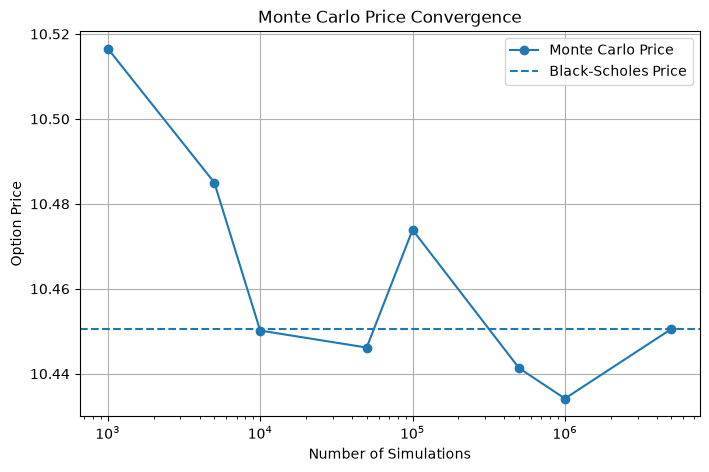

In [40]:
plt.figure(figsize=(8, 5))

plt.plot(
    mc_convergence_nested_df["simulations"],
    mc_convergence_nested_df["price"],
    marker="o",
    label="Monte Carlo Price"
)

plt.axhline(
    bs_price,
    linestyle="--",
    label="Black-Scholes Price"
)

plt.xscale("log")

plt.xlabel("Number of Simulations")
plt.ylabel("Option Price")
plt.title("Monte Carlo Price Convergence")
plt.legend()
plt.grid(True)
plt.show()

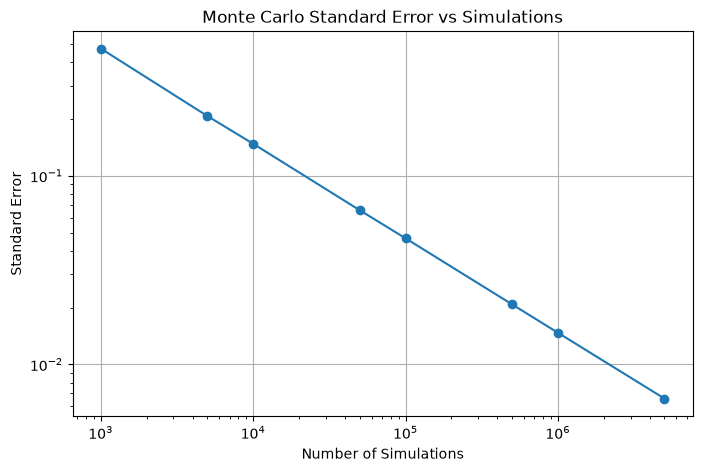

In [41]:
plt.figure(figsize=(8, 5))

plt.loglog(
    mc_convergence_nested_df["simulations"],
    mc_convergence_nested_df["standard_error"],
    marker="o"
)

plt.xlabel("Number of Simulations")
plt.ylabel("Standard Error")
plt.title("Monte Carlo Standard Error vs Simulations")
plt.grid(True)
plt.show()

In [42]:
log_N = np.log(mc_convergence_nested_df["simulations"])
log_SE = np.log(mc_convergence_nested_df["standard_error"])

slope, intercept = np.polyfit(log_N, log_SE, 1)

print(f"Estimated log-log slope: {slope:.4f}")
print(f"Theoretical slope: -0.5000")

Estimated log-log slope: -0.5013
Theoretical slope: -0.5000


## 6. Binomial tree convergence
Self-contained version of the tree (same algorithm as `options_pricing.binomial_call`), run for up to 5,000 steps.

In [43]:
# ============================================
# CRR BINOMIAL TREE PRICING
# ============================================

import numpy as np

def binomial_call_price(S, K, T, r, sigma, N):
    """
    Cox-Ross-Rubinstein binomial tree
    for a European call option.
    """

    dt = T / N

    # Up and down factors
    u = np.exp(sigma * np.sqrt(dt))
    d = 1 / u

    # Risk-neutral probability
    p = (np.exp(r * dt) - d) / (u - d)

    # Asset prices at maturity
    j = np.arange(N + 1)

    ST = S * (u ** j) * (d ** (N - j))

    # Terminal payoff
    option_values = np.maximum(ST - K, 0)

    # Discount backwards through the tree
    discount = np.exp(-r * dt)

    for i in range(N, 0, -1):
        option_values = discount * (
            p * option_values[1:i+1]
            + (1 - p) * option_values[:i]
        )

    return option_values[0]

In [44]:
# Test
binomial_test_price = binomial_call_price(
    S, K, T, r, sigma, 100
)

print(f"Black-Scholes Price: {bs_price:.6f}")
print(f"Binomial Price:      {binomial_test_price:.6f}")

Black-Scholes Price: 10.450584
Binomial Price:      10.430612


In [45]:
# ============================================
# BINOMIAL TREE CONVERGENCE
# ============================================

tree_steps = [
    10,
    25,
    50,
    100,
    250,
    500,
    1000,
    2500,
    5000
]

binomial_convergence = []

for N in tree_steps:

    price = binomial_call_price(
        S, K, T, r, sigma, N
    )

    error_pct = abs(price - bs_price) / bs_price * 100

    binomial_convergence.append({
        "steps": N,
        "price": price,
        "error_pct": error_pct
    })

binomial_convergence_df = pd.DataFrame(
    binomial_convergence
)

binomial_convergence_df

,steps,price,error_pct
0,10,10.253409,1.886732
1,25,10.520966,0.673475
2,50,10.410692,0.381721
3,100,10.430612,0.191108
4,250,10.442589,0.076502
5,500,10.446585,0.038260
6,1000,10.448584,0.019133
7,2500,10.449784,0.007654
8,5000,10.450184,0.003827


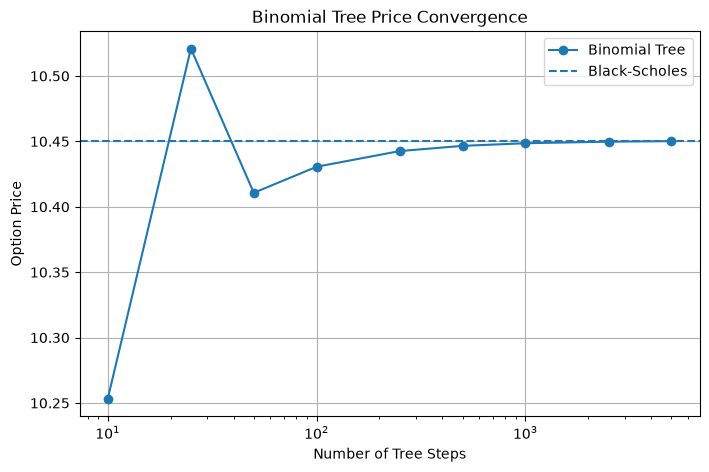

In [46]:
# ============================================
# BINOMIAL CONVERGENCE PLOT
# ============================================

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    binomial_convergence_df["steps"],
    binomial_convergence_df["price"],
    marker="o",
    label="Binomial Tree"
)

plt.axhline(
    bs_price,
    linestyle="--",
    label="Black-Scholes"
)

plt.xscale("log")

plt.xlabel("Number of Tree Steps")
plt.ylabel("Option Price")
plt.title("Binomial Tree Price Convergence")
plt.legend()
plt.grid(True)
plt.show()

## 7. Greeks
Analytical Black-Scholes Greeks (also available as `options_pricing.bs_greeks`) validated against central finite differences.

In [47]:
# ============================================
# BLACK-SCHOLES ANALYTICAL GREEKS
# ============================================

from scipy.stats import norm

def bs_greeks(S, K, T, r, sigma):

    d1 = (
        np.log(S / K)
        + (r + 0.5 * sigma**2) * T
    ) / (sigma * np.sqrt(T))

    d2 = d1 - sigma * np.sqrt(T)

    # Probability density
    pdf_d1 = norm.pdf(d1)

    # Delta
    delta = norm.cdf(d1)

    # Gamma
    gamma = pdf_d1 / (
        S * sigma * np.sqrt(T)
    )

    # Vega
    vega = S * pdf_d1 * np.sqrt(T)

    # Theta
    theta = (
        -S * pdf_d1 * sigma / (2 * np.sqrt(T))
        - r * K * np.exp(-r * T) * norm.cdf(d2)
    )

    # Rho
    rho = (
        K * T * np.exp(-r * T) * norm.cdf(d2)
    )

    return {
        "Delta": delta,
        "Gamma": gamma,
        "Vega": vega,
        "Theta": theta,
        "Rho": rho
    }


greeks = bs_greeks(
    S, K, T, r, sigma
)

greeks

{'Delta': np.float64(0.6368306511756191),
 'Gamma': np.float64(0.018762017345846895),
 'Vega': np.float64(37.52403469169379),
 'Theta': np.float64(-6.414027546438197),
 'Rho': np.float64(53.232481545376345)}

In [48]:
# ============================================
# BLACK-SCHOLES CALL PRICE FUNCTION
# ============================================

from scipy.stats import norm

def bs_call_price(S, K, T, r, sigma):

    d1 = (
        np.log(S / K)
        + (r + 0.5 * sigma**2) * T
    ) / (sigma * np.sqrt(T))

    d2 = d1 - sigma * np.sqrt(T)

    return (
        S * norm.cdf(d1)
        - K * np.exp(-r * T) * norm.cdf(d2)
    )

In [51]:
# ============================================
# FINITE DIFFERENCE GREEKS
# ============================================

epsilon_S = 0.01
epsilon_sigma = 0.0001
epsilon_T = 1e-5
epsilon_r = 0.0001

# Base price
V = bs_call_price(S, K, T, r, sigma)

# --------------------------------------------
# Delta
# --------------------------------------------

V_up = bs_call_price(
    S + epsilon_S, K, T, r, sigma
)

V_down = bs_call_price(
    S - epsilon_S, K, T, r, sigma
)

delta_fd = (V_up - V_down) / (2 * epsilon_S)


# --------------------------------------------
# Gamma
# --------------------------------------------

gamma_fd = (
    V_up
    - 2 * V
    + V_down
) / (epsilon_S ** 2)


# --------------------------------------------
# Vega
# --------------------------------------------

V_sigma_up = bs_call_price(
    S, K, T, r, sigma + epsilon_sigma
)

V_sigma_down = bs_call_price(
    S, K, T, r, sigma - epsilon_sigma
)

vega_fd = (
    V_sigma_up - V_sigma_down
) / (2 * epsilon_sigma)


# --------------------------------------------
# Theta
# --------------------------------------------

V_T_up = bs_call_price(
    S, K, T + epsilon_T, r, sigma
)

V_T_down = bs_call_price(
    S, K, T - epsilon_T, r, sigma
)

dV_dT = (
    V_T_up - V_T_down
) / (2 * epsilon_T)

theta_fd = -dV_dT


# --------------------------------------------
# Rho
# --------------------------------------------

V_r_up = bs_call_price(
    S, K, T, r + epsilon_r, sigma
)

V_r_down = bs_call_price(
    S, K, T, r - epsilon_r, sigma
)

rho_fd = (
    V_r_up - V_r_down
) / (2 * epsilon_r)


# --------------------------------------------
# Results
# --------------------------------------------

finite_difference_greeks = {
    "Delta": delta_fd,
    "Gamma": gamma_fd,
    "Vega": vega_fd,
    "Theta": theta_fd,
    "Rho": rho_fd
}

finite_difference_greeks

{'Delta': np.float64(0.6368306425763137),
 'Gamma': np.float64(0.018762017077733617),
 'Vega': np.float64(37.52403438721075),
 'Theta': np.float64(-6.414027546597366),
 'Rho': np.float64(53.23248077413467)}

In [52]:
# ============================================
# ANALYTICAL VS FINITE DIFFERENCE
# ============================================

greeks_comparison = pd.DataFrame({
    "Greek": [
        "Delta",
        "Gamma",
        "Vega",
        "Theta",
        "Rho"
    ],
    "Analytical": [
        greeks["Delta"],
        greeks["Gamma"],
        greeks["Vega"],
        greeks["Theta"],
        greeks["Rho"]
    ],
    "Finite Difference": [
        finite_difference_greeks["Delta"],
        finite_difference_greeks["Gamma"],
        finite_difference_greeks["Vega"],
        finite_difference_greeks["Theta"],
        finite_difference_greeks["Rho"]
    ]
})

greeks_comparison["Absolute Difference"] = (
    abs(
        greeks_comparison["Analytical"]
        - greeks_comparison["Finite Difference"]
    )
)

greeks_comparison

,Greek,Analytical,Finite Difference,Absolute Difference
0,Delta,0.636831,0.636831,8.599305e-09
1,Gamma,0.018762,0.018762,2.681133e-10
2,Vega,37.524035,37.524034,3.044830e-07
3,Theta,-6.414028,-6.414028,1.591696e-10
4,Rho,53.232482,53.232481,7.712417e-07


## 8. American put
Early-exercise premium of an American put priced on a CRR tree, versus the European Black-Scholes put.

In [53]:
# ============================================
# AMERICAN PUT - CRR BINOMIAL TREE
# ============================================

def binomial_american_put(S, K, T, r, sigma, N):

    dt = T / N

    # CRR up/down factors
    u = np.exp(sigma * np.sqrt(dt))
    d = 1 / u

    # Risk-neutral probability
    p = (np.exp(r * dt) - d) / (u - d)

    discount = np.exp(-r * dt)

    # Stock prices at maturity
    j = np.arange(N + 1)

    ST = S * (u ** j) * (d ** (N - j))

    # Terminal payoff
    option_values = np.maximum(K - ST, 0)

    # Backward induction
    for i in range(N, 0, -1):

        # Stock prices at current nodes
        j = np.arange(i)

        S_current = S * (
            u ** j
        ) * (
            d ** (i - 1 - j)
        )

        # Continuation value
        continuation = discount * (
            p * option_values[1:i+1]
            + (1 - p) * option_values[:i]
        )

        # Immediate exercise value
        exercise = np.maximum(
            K - S_current,
            0
        )

        # American option value
        option_values = np.maximum(
            exercise,
            continuation
        )

    return option_values[0]

In [54]:
# ============================================
# BLACK-SCHOLES EUROPEAN PUT
# ============================================

def bs_put_price(S, K, T, r, sigma):

    d1 = (
        np.log(S / K)
        + (r + 0.5 * sigma**2) * T
    ) / (sigma * np.sqrt(T))

    d2 = d1 - sigma * np.sqrt(T)

    return (
        K * np.exp(-r * T) * norm.cdf(-d2)
        - S * norm.cdf(-d1)
    )

In [55]:
# ============================================
# EUROPEAN VS AMERICAN PUT
# ============================================

N = 1000

european_put = bs_put_price(
    S, K, T, r, sigma
)

american_put = binomial_american_put(
    S, K, T, r, sigma, N
)

early_exercise_premium = (
    american_put - european_put
)

print(f"European Put:          {european_put:.6f}")
print(f"American Put:          {american_put:.6f}")
print(f"Early Exercise Premium: {early_exercise_premium:.6f}")

European Put:          5.573526
American Put:          6.089595
Early Exercise Premium: 0.516069


In [56]:
# ============================================
# AMERICAN PUT CONVERGENCE
# ============================================

american_steps = [
    10,
    25,
    50,
    100,
    250,
    500,
    1000,
    2500,
    5000
]

american_convergence = []

for N in american_steps:

    price = binomial_american_put(
        S, K, T, r, sigma, N
    )

    premium = price - european_put

    american_convergence.append({
        "steps": N,
        "american_put": price,
        "early_exercise_premium": premium
    })

american_convergence_df = pd.DataFrame(
    american_convergence
)

american_convergence_df

,steps,american_put,early_exercise_premium
0,10,6.004259,0.430733
1,25,6.146185,0.572659
2,50,6.073728,0.500202
3,100,6.082354,0.508828
4,250,6.087179,0.513653
5,500,6.088810,0.515284
6,1000,6.089595,0.516069
7,2500,6.090066,0.516540
8,5000,6.090219,0.516693


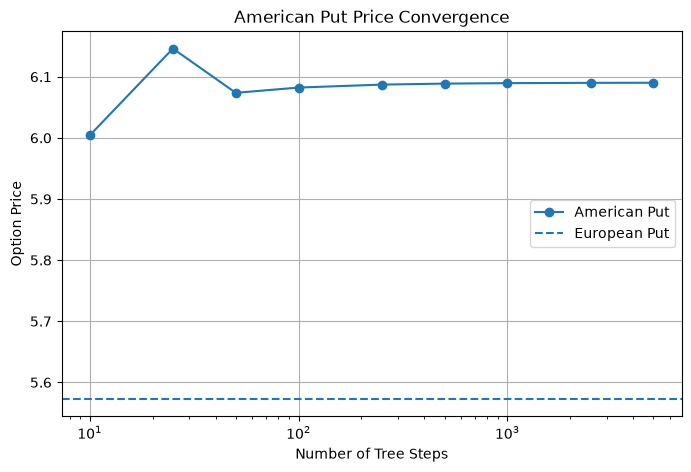

In [57]:
# ============================================
# AMERICAN PUT CONVERGENCE
# ============================================

plt.figure(figsize=(8, 5))

plt.plot(
    american_convergence_df["steps"],
    american_convergence_df["american_put"],
    marker="o",
    label="American Put"
)

plt.axhline(
    european_put,
    linestyle="--",
    label="European Put"
)

plt.xscale("log")

plt.xlabel("Number of Tree Steps")
plt.ylabel("Option Price")
plt.title("American Put Price Convergence")
plt.legend()
plt.grid(True)
plt.show()

## 9. Variance reduction: standard vs antithetic Monte Carlo
Both estimators use the same number of paths. These helper versions return `(price, standard_error, variance)`; the library equivalent is `monte_carlo_price(..., return_stderr=True)`.

**Reading the numbers:** the reported "variance reduction" (~75%) compares the variance of one antithetic *pair average* with that of one plain payoff. Since a pair uses two paths, the variance of the final estimator at equal path count falls by about 50% (compare the standard errors: ratio ~0.71).

In [58]:
# ============================================
# STANDARD VS ANTITHETIC MONTE CARLO
# ============================================

def monte_carlo_standard(
    S, K, T, r, sigma, n_simulations, seed=42
):
    """
    Standard Monte Carlo pricing for a European call.
    """

    rng = np.random.default_rng(seed)

    Z = rng.standard_normal(n_simulations)

    ST = S * np.exp(
        (r - 0.5 * sigma**2) * T
        + sigma * np.sqrt(T) * Z
    )

    payoff = np.maximum(ST - K, 0)

    discounted_payoff = np.exp(-r * T) * payoff

    price = np.mean(discounted_payoff)

    standard_error = (
        np.std(discounted_payoff, ddof=1)
        / np.sqrt(n_simulations)
    )

    variance = np.var(
        discounted_payoff,
        ddof=1
    )

    return price, standard_error, variance


def monte_carlo_antithetic(
    S, K, T, r, sigma, n_simulations, seed=42
):
    """
    Antithetic variates Monte Carlo pricing.

    n_simulations is the TOTAL number of simulated paths.
    """

    # Need an even number of paths
    if n_simulations % 2 != 0:
        n_simulations -= 1

    n_pairs = n_simulations // 2

    rng = np.random.default_rng(seed)

    Z = rng.standard_normal(n_pairs)

    # Antithetic pair: Z and -Z
    Z_antithetic = -Z

    ST_1 = S * np.exp(
        (r - 0.5 * sigma**2) * T
        + sigma * np.sqrt(T) * Z
    )

    ST_2 = S * np.exp(
        (r - 0.5 * sigma**2) * T
        + sigma * np.sqrt(T) * Z_antithetic
    )

    payoff_1 = np.maximum(ST_1 - K, 0)
    payoff_2 = np.maximum(ST_2 - K, 0)

    # Average each antithetic pair
    pair_payoffs = (
        payoff_1 + payoff_2
    ) / 2

    discounted_pair_payoffs = (
        np.exp(-r * T) * pair_payoffs
    )

    price = np.mean(discounted_pair_payoffs)

    standard_error = (
        np.std(
            discounted_pair_payoffs,
            ddof=1
        )
        / np.sqrt(n_pairs)
    )

    variance = np.var(
        discounted_pair_payoffs,
        ddof=1
    )

    return price, standard_error, variance

In [59]:
# ============================================
# ONE-MILLION PATH COMPARISON
# ============================================

N = 1_000_000

mc_price_standard, mc_se_standard, mc_var_standard = (
    monte_carlo_standard(
        S, K, T, r, sigma, N
    )
)

mc_price_antithetic, mc_se_antithetic, mc_var_antithetic = (
    monte_carlo_antithetic(
        S, K, T, r, sigma, N
    )
)

variance_reduction = (
    1 - mc_var_antithetic / mc_var_standard
) * 100

print(f"Black-Scholes Price:       {bs_price:.6f}")
print()
print(f"Standard MC Price:         {mc_price_standard:.6f}")
print(f"Standard MC SE:            {mc_se_standard:.8f}")
print()
print(f"Antithetic MC Price:       {mc_price_antithetic:.6f}")
print(f"Antithetic MC SE:          {mc_se_antithetic:.8f}")
print()
print(f"Variance Reduction:        {variance_reduction:.2f}%")

Black-Scholes Price:       10.450584

Standard MC Price:         10.453195
Standard MC SE:            0.01473146

Antithetic MC Price:       10.456536
Antithetic MC SE:          0.01041622

Variance Reduction:        75.00%


In [60]:
# ============================================
# STANDARD VS ANTITHETIC CONVERGENCE
# ============================================

mc_comparison_results = []

simulation_sizes = [
    1_000,
    5_000,
    10_000,
    50_000,
    100_000,
    500_000,
    1_000_000,
    5_000_000
]

for N in simulation_sizes:

    # Standard MC
    std_price, std_se, std_var = monte_carlo_standard(
        S, K, T, r, sigma, N, seed=42
    )

    # Antithetic MC
    anti_price, anti_se, anti_var = monte_carlo_antithetic(
        S, K, T, r, sigma, N, seed=42
    )

    # Pricing errors
    std_error_pct = (
        abs(std_price - bs_price)
        / bs_price
        * 100
    )

    anti_error_pct = (
        abs(anti_price - bs_price)
        / bs_price
        * 100
    )

    # Variance reduction
    variance_reduction = (
        1 - anti_var / std_var
    ) * 100

    mc_comparison_results.append({
        "simulations": N,
        "standard_price": std_price,
        "antithetic_price": anti_price,
        "standard_se": std_se,
        "antithetic_se": anti_se,
        "standard_error_pct": std_error_pct,
        "antithetic_error_pct": anti_error_pct,
        "variance_reduction_pct": variance_reduction
    })

mc_comparison_df = pd.DataFrame(
    mc_comparison_results
)

mc_comparison_df

,simulations,standard_price,antithetic_price,standard_se,antithetic_se,standard_error_pct,antithetic_error_pct,variance_reduction_pct
0,1000,9.911980,10.000398,0.448345,0.313601,5.153817,4.307757,75.537509
1,5000,10.168920,10.450949,0.205861,0.150468,2.695196,0.003501,73.287666
2,10000,10.345182,10.410052,0.147663,0.104872,1.008571,0.387843,74.779871
3,50000,10.457692,10.454935,0.066143,0.046749,0.068015,0.041641,75.022969
4,100000,10.420541,10.467314,0.046770,0.033077,0.287471,0.160092,74.991585
5,500000,10.450050,10.455650,0.020856,0.014761,0.005108,0.048484,74.953540
6,1000000,10.453195,10.456536,0.014731,0.010416,0.024991,0.056955,75.002364
7,5000000,10.458798,10.449897,0.006583,0.004651,0.078606,0.006574,75.044154


In [61]:
# ============================================
# FORMAT MC COMPARISON RESULTS
# ============================================

display(
    mc_comparison_df.style.format({
        "simulations": "{:,.0f}",
        "standard_price": "{:.6f}",
        "antithetic_price": "{:.6f}",
        "standard_se": "{:.8f}",
        "antithetic_se": "{:.8f}",
        "standard_error_pct": "{:.4f}%",
        "antithetic_error_pct": "{:.4f}%",
        "variance_reduction_pct": "{:.2f}%"
    })
)

,simulations,standard_price,antithetic_price,standard_se,antithetic_se,standard_error_pct,antithetic_error_pct,variance_reduction_pct
0,"1,000",9.911980,10.000398,0.44834528,0.31360136,5.1538%,4.3078%,75.54%
1,"5,000",10.168920,10.450949,0.20586057,0.15046798,2.6952%,0.0035%,73.29%
2,"10,000",10.345182,10.410052,0.14766266,0.10487195,1.0086%,0.3878%,74.78%
3,"50,000",10.457692,10.454935,0.06614344,0.04674898,0.0680%,0.0416%,75.02%
4,"100,000",10.420541,10.467314,0.04676990,0.03307688,0.2875%,0.1601%,74.99%
5,"500,000",10.450050,10.455650,0.02085581,0.01476098,0.0051%,0.0485%,74.95%
6,"1,000,000",10.453195,10.456536,0.01473146,0.01041622,0.0250%,0.0570%,75.00%
7,"5,000,000",10.458798,10.449897,0.00658327,0.00465096,0.0786%,0.0066%,75.04%


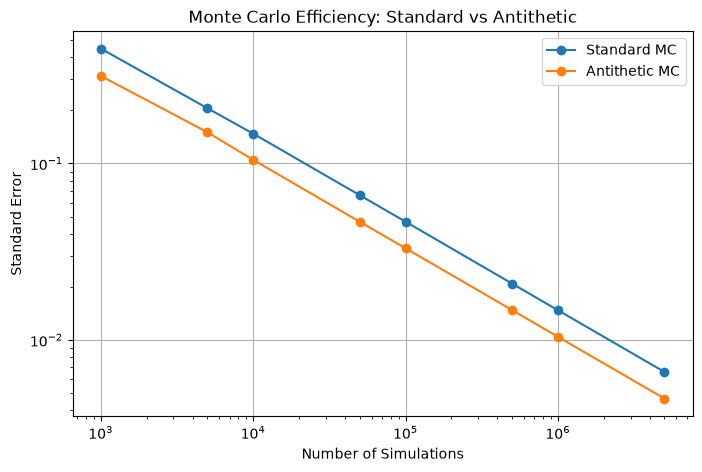

In [62]:
# ============================================
# STANDARD ERROR CONVERGENCE
# ============================================

plt.figure(figsize=(8, 5))

plt.loglog(
    mc_comparison_df["simulations"],
    mc_comparison_df["standard_se"],
    marker="o",
    label="Standard MC"
)

plt.loglog(
    mc_comparison_df["simulations"],
    mc_comparison_df["antithetic_se"],
    marker="o",
    label="Antithetic MC"
)

plt.xlabel("Number of Simulations")
plt.ylabel("Standard Error")
plt.title("Monte Carlo Efficiency: Standard vs Antithetic")
plt.legend()
plt.grid(True)
plt.show()

In [63]:
# ============================================
# ANTITHETIC VARIANCE REDUCTION SUMMARY
# ============================================

avg_variance_reduction = (
    mc_comparison_df["variance_reduction_pct"].mean()
)

max_variance_reduction = (
    mc_comparison_df["variance_reduction_pct"].max()
)

min_variance_reduction = (
    mc_comparison_df["variance_reduction_pct"].min()
)

print(
    f"Average variance reduction: "
    f"{avg_variance_reduction:.2f}%"
)

print(
    f"Minimum variance reduction: "
    f"{min_variance_reduction:.2f}%"
)

print(
    f"Maximum variance reduction: "
    f"{max_variance_reduction:.2f}%"
)

Average variance reduction: 74.83%
Minimum variance reduction: 73.29%
Maximum variance reduction: 75.54%


## 10. Cross-validation
Black-Scholes, standard MC (5M paths), antithetic MC (5M paths) and a 5,000-step binomial tree side by side.

In [64]:
# ============================================
# THREE-MODEL CROSS-VALIDATION
# ============================================

# Black-Scholes benchmark
bs_final = bs_call_price(
    S, K, T, r, sigma
)

# Standard Monte Carlo - 5M simulations
mc_final, mc_se_final, _ = monte_carlo_standard(
    S, K, T, r, sigma,
    5_000_000,
    seed=42
)

# Antithetic Monte Carlo - 5M simulations
anti_final, anti_se_final, _ = monte_carlo_antithetic(
    S, K, T, r, sigma,
    5_000_000,
    seed=42
)

# CRR Binomial Tree - 5,000 steps
binomial_final = binomial_call_price(
    S, K, T, r, sigma,
    5_000
)

# Relative errors vs Black-Scholes
mc_error_final = (
    abs(mc_final - bs_final)
    / bs_final
    * 100
)

anti_error_final = (
    abs(anti_final - bs_final)
    / bs_final
    * 100
)

binomial_error_final = (
    abs(binomial_final - bs_final)
    / bs_final
    * 100
)

three_model_comparison = pd.DataFrame({
    "Method": [
        "Black-Scholes",
        "Standard Monte Carlo",
        "Antithetic Monte Carlo",
        "CRR Binomial Tree"
    ],
    "Price": [
        bs_final,
        mc_final,
        anti_final,
        binomial_final
    ],
    "Relative Error (%)": [
        0,
        mc_error_final,
        anti_error_final,
        binomial_error_final
    ]
})

three_model_comparison

,Method,Price,Relative Error (%)
0,Black-Scholes,10.450584,0.000000
1,Standard Monte Carlo,10.458798,0.078606
2,Antithetic Monte Carlo,10.449897,0.006574
3,CRR Binomial Tree,10.450184,0.003827


In [65]:
display(
    three_model_comparison.style.format({
        "Price": "{:.6f}",
        "Relative Error (%)": "{:.6f}%"
    })
)

,Method,Price,Relative Error (%)
0,Black-Scholes,10.450584,0.000000%
1,Standard Monte Carlo,10.458798,0.078606%
2,Antithetic Monte Carlo,10.449897,0.006574%
3,CRR Binomial Tree,10.450184,0.003827%


## 11. Parameter sensitivity
Call price as a function of volatility, strike, maturity and spot.

In [66]:
# ============================================
# VOLATILITY SENSITIVITY
# ============================================

volatilities = np.linspace(
    0.10,
    0.50,
    9
)

volatility_results = []

for sigma_test in volatilities:

    price = bs_call_price(
        S,
        K,
        T,
        r,
        sigma_test
    )

    volatility_results.append({
        "volatility": sigma_test,
        "option_price": price
    })

volatility_df = pd.DataFrame(
    volatility_results
)

volatility_df

,volatility,option_price
0,0.10,6.804958
1,0.15,8.591658
2,0.20,10.450584
3,0.25,12.335999
4,0.30,14.231255
5,0.35,16.128429
6,0.40,18.022951
7,0.45,19.911770
8,0.50,21.792604


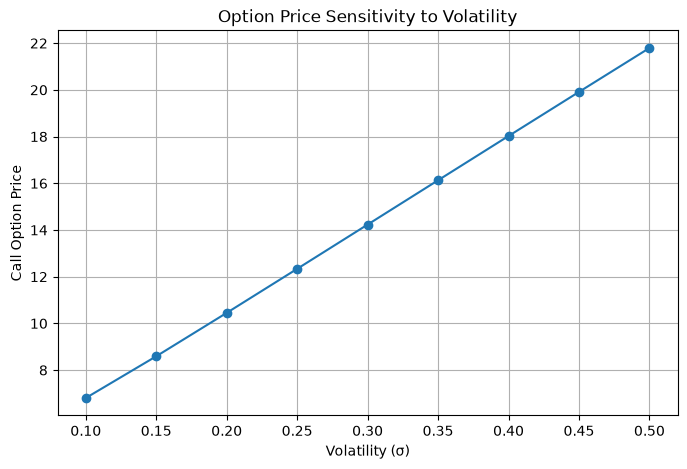

In [67]:
# ============================================
# VOLATILITY VS OPTION PRICE
# ============================================

plt.figure(figsize=(8, 5))

plt.plot(
    volatility_df["volatility"],
    volatility_df["option_price"],
    marker="o"
)

plt.xlabel("Volatility (σ)")
plt.ylabel("Call Option Price")
plt.title("Option Price Sensitivity to Volatility")
plt.grid(True)
plt.show()

In [68]:
# ============================================
# STRIKE PRICE SENSITIVITY
# ============================================

strikes = np.array([
    80,
    85,
    90,
    95,
    100,
    105,
    110,
    115,
    120
])

strike_results = []

for K_test in strikes:

    price = bs_call_price(
        S,
        K_test,
        T,
        r,
        sigma
    )

    strike_results.append({
        "strike": K_test,
        "option_price": price
    })

strike_df = pd.DataFrame(strike_results)

strike_df

,strike,option_price
0,80,24.588835
1,85,20.469288
2,90,16.699448
3,95,13.346465
4,100,10.450584
5,105,8.021352
6,110,6.040088
7,115,4.466579
8,120,3.247477


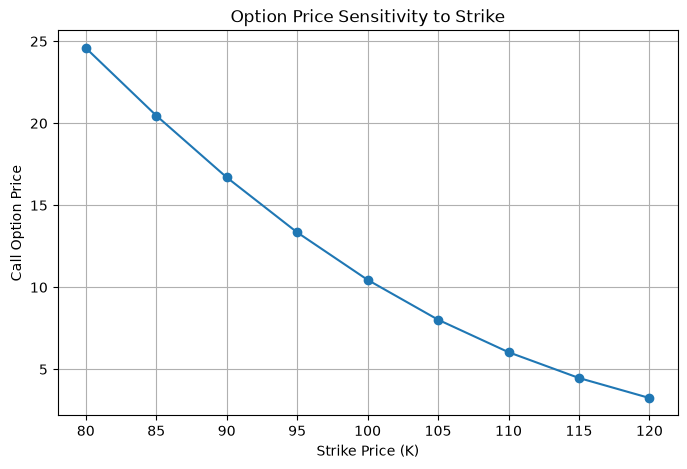

In [70]:
# ============================================
# STRIKE VS OPTION PRICE
# ============================================

plt.figure(figsize=(8, 5))

plt.plot(
    strike_df["strike"],
    strike_df["option_price"],
    marker="o"
)

plt.xlabel("Strike Price (K)")
plt.ylabel("Call Option Price")
plt.title("Option Price Sensitivity to Strike")
plt.grid(True)
plt.show()

In [71]:
# ============================================
# MATURITY SENSITIVITY
# ============================================

maturities = np.array([
    0.10,
    0.25,
    0.50,
    0.75,
    1.00,
    1.50,
    2.00,
    3.00,
    5.00
])

maturity_results = []

for T_test in maturities:

    price = bs_call_price(
        S,
        K,
        T_test,
        r,
        sigma
    )

    maturity_results.append({
        "maturity": T_test,
        "option_price": price
    })

maturity_df = pd.DataFrame(
    maturity_results
)

maturity_df

,maturity,option_price
0,0.10,2.773654
1,0.25,4.614997
2,0.50,6.888729
3,0.75,8.772268
4,1.00,10.450584
5,1.50,13.442905
6,2.00,16.126780
7,3.00,20.924361
8,5.00,29.138620


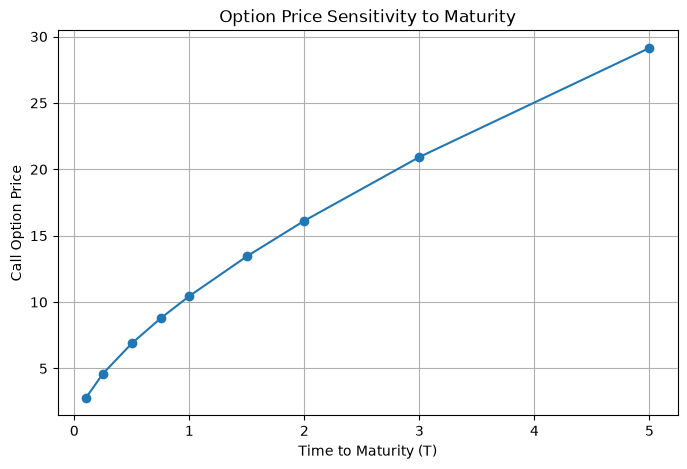

In [72]:
# ============================================
# MATURITY VS OPTION PRICE
# ============================================

plt.figure(figsize=(8, 5))

plt.plot(
    maturity_df["maturity"],
    maturity_df["option_price"],
    marker="o"
)

plt.xlabel("Time to Maturity (T)")
plt.ylabel("Call Option Price")
plt.title("Option Price Sensitivity to Maturity")
plt.grid(True)
plt.show()

In [73]:
# ============================================
# UNDERLYING PRICE SENSITIVITY
# ============================================

underlying_prices = np.array([
    70,
    80,
    90,
    95,
    100,
    105,
    110,
    120,
    130
])

underlying_results = []

for S_test in underlying_prices:

    price = bs_call_price(
        S_test,
        K,
        T,
        r,
        sigma
    )

    underlying_results.append({
        "underlying_price": S_test,
        "option_price": price
    })

underlying_df = pd.DataFrame(
    underlying_results
)

underlying_df

,underlying_price,option_price
0,70,0.441448
1,80,1.859420
2,90,5.091222
3,95,7.510872
4,100,10.450584
5,105,13.857906
6,110,17.662954
7,120,26.169044
8,130,35.440271


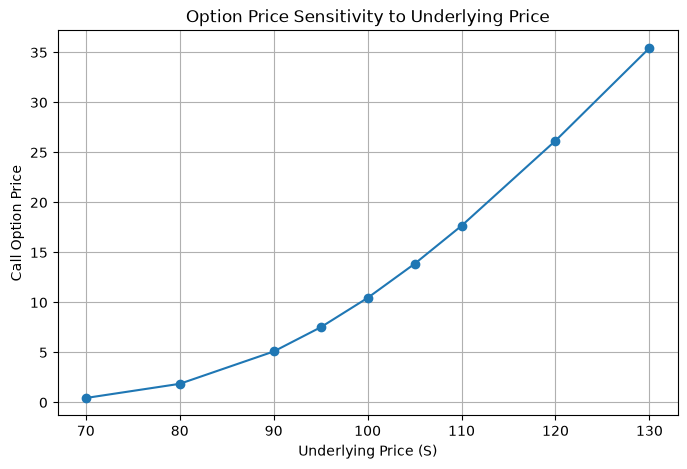

In [74]:
# ============================================
# UNDERLYING PRICE VS OPTION PRICE
# ============================================

plt.figure(figsize=(8, 5))

plt.plot(
    underlying_df["underlying_price"],
    underlying_df["option_price"],
    marker="o"
)

plt.xlabel("Underlying Price (S)")
plt.ylabel("Call Option Price")
plt.title("Option Price Sensitivity to Underlying Price")
plt.grid(True)
plt.show()